# Neural network survival regression on MNIST

Survival analysis models the time until an event. For many subjects, follow-up ends before the event happens, so their outcome is *censored*. In this tutorial a small convolutional neural network learns a survival distribution from handwritten digits with simulated outcomes. Because we simulated the data, we can compare the network's predictions with the true distributions.

Instructions for running the notebook are at the end.

In [1]:
import sys
from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import survjax

# Make the example package (examples/survival_mnist) importable from the repository root.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))
from examples.survival_mnist import data, model

CONFIG = "full"  # or "smoke" for a quick one-epoch run on 5,000 images

## Censored data and the likelihood

For subject $i$ we observe $t_i=\min(T_i, C_i)$, the earlier of the event time $T_i$ and the censoring time $C_i$, and the event indicator $\delta_i=\mathbb{1}[T_i\le C_i]$. An observed event contributes the density $f(t_i)$. A censored observation tells us only that $T_i>t_i$, and contributes the survival function $S(t_i)=P(T_i>t_i)$. With independent, non-informative censoring, the log likelihood is

$$
\ell(\theta)=\sum_{i}\Big[\delta_i\log f_\theta(t_i)+(1-\delta_i)\log S_\theta(t_i)\Big].
$$

In `survjax`, `dist.log_likelihood(data)` returns these terms, one per observation. Here `data` is a `survjax.SurvivalData` container that can be sliced like an array: `data[idx]` stays aligned with `images[idx]`. `survjax.SurvivalData` can represent more types of survival data (left / interval censoring, combined with left/right truncation). For the common 'right-censored' data type, `dist.log_likelihood(time=time, event=event)` also works without constructing a `survjax.SurvivalData` object first.

## A simulated world where we know the answer

Event times follow a Weibull distribution, $S(t)=\exp[-(t/b)^k]$, with shared shape $k=1.38$ and a scale depending on the digit $d$: $\log b_d=\log 10-0.2\,d$. Zeros survive longest and nines shortest. Censoring times are Uniform$(0,7)$, which censors about half of the observations. The digit labels are used only to simulate outcomes and to define an *oracle* that knows each image's true parameters. The network sees only the pixels and the (possibly censored) outcomes.

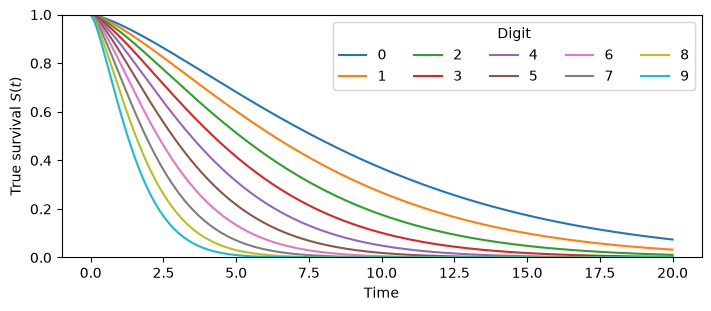

,images,censored fraction
train,50000,0.500
validation,10000,0.507
test,10000,0.499


In [2]:
pixels, labels = data.load_mnist()
outcomes = data.generate_outcomes(labels)
observations = survjax.SurvivalData(outcomes.time, outcomes.event)
cohorts = data.split_indices(CONFIG)
train, validation, test = cohorts["train"], cohorts["validation"], cohorts["test"]

times = jnp.linspace(0, 20, 201)
truth = survjax.Weibull.from_log(log_shape=jnp.log(data.TRUE_SHAPE), log_scale=data.TRUE_LOG_SCALES)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(times, truth.survival_grid(times), label=[str(d) for d in range(10)])  # grid shape: (time, digit)
ax.set(xlabel="Time", ylabel="True survival $S(t)$", ylim=(0, 1))
ax.legend(title="Digit", ncols=5)
plt.show()

pd.DataFrame.from_dict(
    {
        name: {"images": len(idx), "censored fraction": float(1 - outcomes.event[idx].mean())}
        for name, idx in cohorts.items()
    },
    orient="index",
).round(3)

## A Weibull model with a neural network scale

The network $g_\phi$ maps each image to its log scale, $\log b_i=g_\phi(x_i)$, and one shape $k$ is shared by all images. On the log scale both parameters are unconstrained, so `Weibull.from_log` takes the network output directly. The loss is the mean negative log likelihood:

```python
def loss(params, images, data):
    cnn, log_k = params
    dist = survjax.Weibull.from_log(log_shape=log_k, log_scale=jax.vmap(cnn)(images))
    return -dist.log_likelihood(data).mean()
```

The [CNN](model.py) has two convolution and pooling layers followed by two dense layers. We first fit an intercept-only Weibull by maximum likelihood. It is a baseline without image information, and it provides the network's starting values. Adam then trains the network and $\log k$ jointly, in minibatches of 128. The epoch with the lowest validation loss is kept.

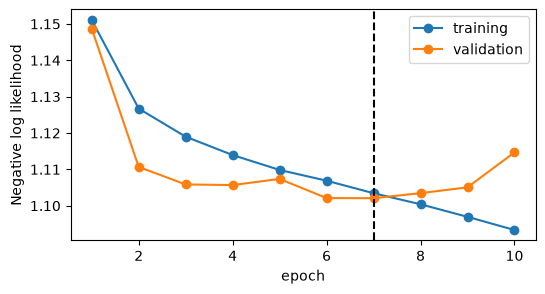

In [3]:
intercept = model.fit_intercept(outcomes.time[train], outcomes.event[train])
result = model.train(
    pixels[train],
    observations[train],
    pixels[validation],
    observations[validation],
    initial_intercept=intercept,
    epochs=1 if CONFIG == "smoke" else 10,
)
cnn, log_k = result.params

history = pd.DataFrame(
    {"training": result.training_nll, "validation": result.validation_nll},
    index=pd.RangeIndex(1, len(result.training_nll) + 1, name="epoch"),
)
ax = history.plot(marker="o", ylabel="Negative log likelihood", figsize=(6, 3))
ax.axvline(result.selected_epoch, color="black", linestyle="--")
plt.show()

## Evaluation on held-out images

We compare the CNN with the intercept-only baseline and the oracle on the test images, using two metrics where higher is better. The **mean log likelihood** scores the whole predicted distribution, including the censored observations. **Harrell's C** scores only the ranking: it is the fraction of comparable pairs in which the subject with the earlier event got the higher risk score. Because the shape is shared, the predicted curves do not cross, and $-\log b_i$ is a valid risk score.

In [4]:
candidates = {
    "CNN": (log_k, model.predict(cnn, pixels[test])),
    "Intercept only": (intercept[0], intercept[1]),
    "Oracle": (jnp.log(data.TRUE_SHAPE), data.TRUE_LOG_SCALES[labels[test]]),
}
metrics = pd.DataFrame.from_dict(
    {
        name: model.evaluate(log_shape, log_scale, observations[test])
        for name, (log_shape, log_scale) in candidates.items()
    },
    orient="index",
)
metrics[["mean_log_likelihood", "shape", "concordance"]].rename(
    columns={"mean_log_likelihood": "mean log likelihood", "shape": "shape k", "concordance": "Harrell's C"}
).round(3)

,mean log likelihood,shape k,Harrell's C
CNN,-1.127,1.368,0.689
Intercept only,-1.238,1.188,0.500
Oracle,-1.111,1.380,0.698


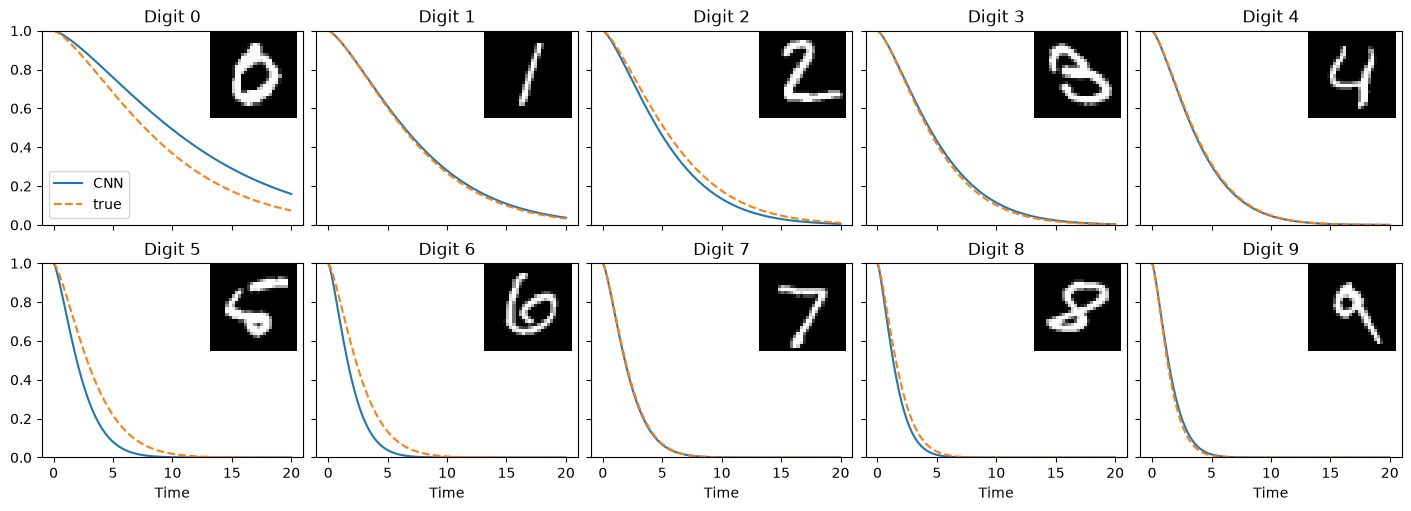

In [5]:
test_labels = np.asarray(labels[test])
first = np.array([np.flatnonzero(test_labels == d)[0] for d in range(10)])  # first test image per digit
predicted = survjax.Weibull.from_log(log_shape=log_k, log_scale=candidates["CNN"][1][first])
curves, true_curves = predicted.survival_grid(times), truth.survival_grid(times)

fig, axes = plt.subplots(2, 5, figsize=(14, 5), sharex=True, sharey=True, layout="constrained")
for d, ax in enumerate(axes.flat):
    ax.plot(times, curves[:, d], label="CNN")
    ax.plot(times, true_curves[:, d], "--", label="true")
    ax.set(title=f"Digit {d}", ylim=(0, 1))
    image = ax.inset_axes([0.62, 0.55, 0.38, 0.45])
    image.imshow(pixels[test[first[d]], 0], cmap="gray")
    image.set_axis_off()
for ax in axes[1]:
    ax.set_xlabel("Time")
axes[0, 0].legend(loc="lower left")
plt.show()

## Discussion

In our full run, the CNN reached a mean log likelihood of −1.127 and $C=0.689$, close to the oracle's −1.111 and 0.698, and well above the intercept-only baseline's −1.238 and 0.5. The learned shape was 1.368, against a true value of 1.38. The intercept-only model ranks every image the same, so its $C$ is exactly 0.5. It also underestimates the shape (1.19): short-lived digits leave the risk set first, which makes the hazard of the mixed population rise more slowly than that of any single digit. Once the network explains the differences between images, the shared shape returns to its true value.

To go further, let the network predict $\log k_i$ as well; the curves may then cross, so $C$ needs a different risk score. Or swap the CNN for any network or tabular model that outputs the distribution's parameters. See the [likelihood](../../docs/likelihood.md) and [concordance](../../docs/concordance.md) documentation.

## Running this notebook

From the repository root, run `uv run --group docs --group examples jupyter lab examples/survival_mnist/survival-mnist.ipynb`, then **Restart Kernel and Run All Cells** in a fresh Python 3 kernel (JAX's default float32). The full configuration takes about half a minute on a laptop CPU. The first run downloads MNIST into `~/.cache/survjax-examples/mnist`; set `SURVJAX_EXAMPLES_DATA` to use another location. The [command-line runner](README.md) reproduces the full experiment and saves its outputs.

## References

Harrell, F. E., Califf, R. M., Pryor, D. B., Lee, K. L. and Rosati, R. A. (1982). Evaluating the yield of medical tests. *JAMA* 247(18), 2543–2546. Kalbfleisch, J. D. and Prentice, R. L. (2002). *The Statistical Analysis of Failure Time Data*, 2nd ed. Wiley.

MNIST is by Y. LeCun, C. Cortes and C. J. C. Burges, under CC BY-SA 3.0 ([dataset](http://yann.lecun.com/exdb/mnist/)). The survival outcomes are synthetic.